<center><h1>Zhang_Zhengshu_HW6</h1></center>

Name: Zhengshu Zhang
<br>
Github Username: forestzs
<br>
USC ID: 4664738582

## 1. Tree-Based Methods

Import packages

In [1]:
import math

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.ensemble import RandomForestClassifier
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import StratifiedKFold, GridSearchCV, cross_validate
from sklearn.metrics import confusion_matrix, roc_curve, roc_auc_score
from sklearn.svm import SVC
from xgboost import XGBClassifier
from imblearn.ensemble import BalancedRandomForestClassifier
from imblearn.over_sampling import SMOTE
from imblearn.pipeline import Pipeline

### (a) Download the APS Failure data

The APS Failure at Scania Trucks data set comes from the UCI Machine Learning Repository [1]. It has a training file and a test file. Each file starts with 20 lines of licence text, then a header line, and missing values are written as the string "na". The two csv files are stored compressed in the data folder because of their size, and pandas reads the compressed files directly. The first column is the class, with the values "neg" and "pos". The positive class "pos" is an APS failure, and it is coded as label 1 below. The other 170 columns are the numeric features.

In [2]:
train = pd.read_csv("data/APS/aps_failure_training_set.csv.gz", skiprows=20, na_values="na")
test = pd.read_csv("data/APS/aps_failure_test_set.csv.gz", skiprows=20, na_values="na")

assert train.shape == (60000, 171) and test.shape == (16000, 171)
assert list(train.columns) == list(test.columns) and train.columns[0] == "class"
features = list(train.columns[1:])
assert all(pd.api.types.is_numeric_dtype(train[f]) for f in features)
assert all(pd.api.types.is_numeric_dtype(test[f]) for f in features)

X_train_raw = train[features]
X_test_raw = test[features]
y_train = (train["class"] == "pos").astype(int).values
y_test = (test["class"] == "pos").astype(int).values

print("train shape:", train.shape, "  test shape:", test.shape)
print("class values, train:", sorted(train["class"].unique()), "  test:", sorted(test["class"].unique()))
print("first five columns:", list(train.columns[:5]))
print("number of numeric features:", len(features))
print(train.iloc[:5, :8].to_string())

train shape: (60000, 171)   test shape: (16000, 171)
class values, train: ['neg', 'pos']   test: ['neg', 'pos']
first five columns: ['class', 'aa_000', 'ab_000', 'ac_000', 'ad_000']
number of numeric features: 170
  class  aa_000  ab_000        ac_000  ad_000  ae_000  af_000  ag_000
0   neg   76698     NaN  2.130706e+09   280.0     0.0     0.0     0.0
1   neg   33058     NaN  0.000000e+00     NaN     0.0     0.0     0.0
2   neg   41040     NaN  2.280000e+02   100.0     0.0     0.0     0.0
3   neg      12     0.0  7.000000e+01    66.0     0.0    10.0     0.0
4   neg   60874     NaN  1.368000e+03   458.0     0.0     0.0     0.0


The training set has 60000 rows and 171 columns, and the test set has 16000 rows and 171 columns, as the checks in the code confirm. The column order is the same in both files, the first column is the class, and all 170 features are numeric. The first rows already show missing values, printed as NaN.

### (b) Data Preparation

#### (i) Research what types of techniques are usually used

Techniques for missing values are called imputation techniques. The simplest one is to delete every row or every column that has a missing value, but that throws away data that may be useful. The usual alternatives fill each missing value with a summary of the observed values of the same feature, which is the mean, the median or the most frequent value. Another option is k-nearest-neighbour imputation, which fills a missing value with the average of the k rows that are closest on the other features. A further option is model-based or iterative imputation, which predicts each feature with missing values from the other features and repeats the predictions in rounds. The scikit-learn user guide describes all of these and says that discarding rows loses data that may be valuable, so imputing is the better strategy [2].

In [3]:
missing = X_train_raw.isna().mean()
print("features with at least one missing value:", int((missing > 0).sum()), "of", len(features))
print("features with no missing value:", list(missing.index[missing == 0]))
print()
print("five features with the largest share of missing values:")
print(missing.sort_values(ascending=False).head(5).round(4).to_string())
print()
print("training rows with no missing value:", int(X_train_raw.notna().all(axis=1).sum()), "of", len(X_train_raw))
print("test rows with no missing value:", int(X_test_raw.notna().all(axis=1).sum()), "of", len(X_test_raw))
print("share of all training cells that are missing: %.4f" % X_train_raw.isna().values.mean())

features with at least one missing value: 169 of 170
features with no missing value: ['aa_000']

five features with the largest share of missing values:
br_000    0.8211
bq_000    0.8120
bp_000    0.7957
bo_000    0.7722
ab_000    0.7722

training rows with no missing value: 591 of 60000
test rows with no missing value: 165 of 16000
share of all training cells that are missing: 0.0833


169 of the 170 features have at least one missing value, and aa_000 is the only complete feature. The feature br_000 is missing in 82.11 percent of the training rows, and bq_000, bp_000, bo_000 and ab_000 are each missing in more than 77 percent. Only 591 of the 60000 training rows and 165 of the 16000 test rows have no missing value at all, while 8.33 percent of all the values in the training set are missing. Deleting rows with missing values would keep less than 1 percent of the data, so deleting is not an option here, as the handout says.

In [4]:
train_medians = X_train_raw.median()
X_train = X_train_raw.fillna(train_medians)

test_medians = X_test_raw.median()
X_test = X_test_raw.fillna(test_medians)

assert X_train.isna().sum().sum() == 0 and X_test.isna().sum().sum() == 0
print("missing values left, train:", int(X_train.isna().sum().sum()), "  test:", int(X_test.isna().sum().sum()))
print("features whose train median and test median differ:", int((train_medians != test_medians).sum()), "of", len(features))
print("features kept:", X_train.shape[1])

missing values left, train: 0   test: 0
features whose train median and test median differ: 107 of 170
features kept: 170


Median imputation is used, and all 170 features are kept. The features are counts and sums with very skewed distributions, so the median is pulled much less by extreme values than the mean. The training set is filled with the medians of the training set. The test set is filled with the medians of the test set, because footnote 1 of the handout says that at prediction time the training data are not available, so only the statistics of the test data can fill its missing values. Neither step uses the class labels. The two sets of medians differ for 107 of the 170 features, so this choice does change the filled test values. In the cross-validations of parts (e) and (f) the imputation is repeated inside each fold, so the held-out rows are filled with the medians of the rows the model is fitted on.

#### (ii) Calculate the coefficient of variation

The coefficient of variation (CV) of a feature is $CV = s / m$, where $s$ is the sample standard deviation (with $n - 1$ in the denominator) and $m$ is the sample mean. It is computed for each of the 170 features on the imputed training set. A feature with mean 0 would have no CV, so the means are checked first. In this notebook CV always means the coefficient of variation, and cross-validation is always written out in full.

In [5]:
m = X_train.mean()
s = X_train.std(ddof=1)
print("features with sample mean 0:", list(m.index[m == 0]))
print("features with sample standard deviation 0:", list(s.index[s == 0]))
cv = (s / m).sort_values(ascending=False)
cv.name = "CV"
print()
print("CV of all 170 features, highest first:")
print(cv.round(4).to_string())

features with sample mean 0: []
features with sample standard deviation 0: ['cd_000']

CV of all 170 features, highest first:
cf_000    244.8875
co_000    244.5074
ad_000    244.3228
cs_009    237.9306
dh_000    123.2161
dj_000    117.4942
ag_000     92.9178
as_000     87.3325
ay_009     84.7337
ak_000     80.4250
az_009     77.8385
ch_000     77.4539
au_000     68.8828
cr_000     58.0781
ay_001     52.8247
df_000     52.2928
dz_000     51.3322
ef_000     49.3667
cs_008     48.1022
aj_000     44.2660
eg_000     42.4817
dl_000     39.7391
ay_002     39.2487
dg_000     38.4862
ay_000     37.4283
dk_000     37.0391
cy_000     36.6009
dm_000     36.2614
ag_001     35.2493
ea_000     34.9465
cn_009     34.2721
ay_004     33.7523
ag_009     33.3576
da_000     29.3675
ay_003     28.7351
cn_000     26.3356
ae_000     24.2001
at_000     23.7082
az_008     22.6797
dq_000     22.0301
af_000     19.4713
ai_000     18.2038
ag_002     17.5659
az_007     16.2294
cl_000     14.9707
cz_000     14.5056


In [6]:
n = len(X_train)
print("number of training rows n = %d, sqrt(n) = %.4f" % (n, math.sqrt(n)))
for f in cv.index[:4]:
    col = X_train[f]
    print("%s: CV %.4f   largest value %.0f   share of the column total in its largest value %.4f"
          % (f, cv[f], col.max(), col.max() / col.sum()))

number of training rows n = 60000, sqrt(n) = 244.9490
cf_000: CV 244.8875   largest value 8584297736   share of the column total in its largest value 0.9997
co_000: CV 244.5074   largest value 8584297742   share of the column total in its largest value 0.9982
ad_000: CV 244.3228   largest value 8584297742   share of the column total in its largest value 0.9974
cs_009: CV 237.9306   largest value 44902992   share of the column total in its largest value 0.9713


No feature has a sample mean of 0, so the CV is defined for all 170 features. The feature cd_000 is constant, so its sample standard deviation is 0 and its CV is 0. The highest CVs belong to cf_000, co_000 and ad_000, between 244.32 and 244.89, followed by cs_009 at 237.93. The output above shows why. For each of these four features, a single value holds more than 97 percent of the column total. If one of the $n$ values holds the whole total, the CV is exactly $\sqrt{n}$, which is 244.95 for the 60000 training rows, and the CVs of cf_000, co_000 and ad_000 are very close to that value. The lowest CV among the non-constant features is 0.69 for br_000.

#### (iii) Plot a correlation matrix

The correlation matrix of the 170 imputed training features is drawn as a heat map with a colour bar. Only every tenth feature name is shown on the axes so that the labels stay readable. The feature cd_000 is constant, so its correlation with any feature is undefined and its row and column are left empty. The five most correlated pairs are printed below the figure.

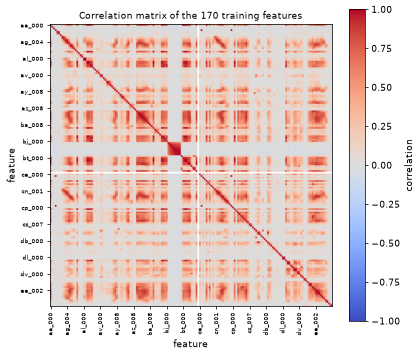

five most correlated pairs:
  bv_000 and cq_000: 1.000000
  bu_000 and cq_000: 1.000000
  bu_000 and bv_000: 1.000000
  cf_000 and co_000: 1.000000
  ad_000 and cf_000: 1.000000
pairs with a defined correlation: 14196 of 14365
pairs with correlation above 0.9999: 6
pairs with correlation above 0.9: 130
pairs with correlation below -0.5: 0   lowest correlation: -0.1056
features whose correlation is undefined: ['cd_000']


In [7]:
corr = X_train.corr()

fig, ax = plt.subplots(figsize=(6.5, 5.6), dpi=66)
cmap = plt.get_cmap("coolwarm").copy()
cmap.set_bad("white")
im = ax.imshow(np.ma.masked_invalid(corr.values), cmap=cmap, vmin=-1, vmax=1)
ticks = np.arange(0, len(features), 10)
ax.set_xticks(ticks)
ax.set_xticklabels([features[i] for i in ticks], rotation=90, fontsize=7)
ax.set_yticks(ticks)
ax.set_yticklabels([features[i] for i in ticks], fontsize=7)
ax.set_xlabel("feature")
ax.set_ylabel("feature")
ax.set_title("Correlation matrix of the 170 training features", fontsize=10)
fig.colorbar(im, ax=ax, label="correlation")
plt.tight_layout()
plt.show()

upper = corr.where(np.triu(np.ones(corr.shape, dtype=bool), k=1))
pairs = upper.stack().dropna().sort_values(ascending=False)
print("five most correlated pairs:")
for (a, b), r in pairs.head(5).items():
    print("  %s and %s: %.6f" % (a, b, r))
print("pairs with a defined correlation:", len(pairs), "of", len(features) * (len(features) - 1) // 2)
print("pairs with correlation above 0.9999:", int((pairs > 0.9999).sum()))
print("pairs with correlation above 0.9:", int((pairs > 0.9).sum()))
print("pairs with correlation below -0.5:", int((pairs < -0.5).sum()), "  lowest correlation: %.4f" % pairs.min())
print("features whose correlation is undefined:", list(corr.index[corr.isna().all(axis=1)]))

In [8]:
big_row = X_train["cf_000"].idxmax()
print("training row with the largest cf_000:", big_row)
print(X_train.loc[big_row, ["cf_000", "co_000", "ad_000"]].to_string())
print()
print("correlations of cf_000, co_000 and ad_000 without that row:")
print(X_train.drop(index=big_row)[["cf_000", "co_000", "ad_000"]].corr().round(4).to_string())
print()
for a, b in [("bv_000", "cq_000"), ("bu_000", "cq_000"), ("bu_000", "bv_000")]:
    print("%s and %s are equal in %.4f of the training rows" % (a, b, (X_train[a] == X_train[b]).mean()))

training row with the largest cf_000: 45977
cf_000    8.584298e+09
co_000    8.584298e+09
ad_000    8.584298e+09

correlations of cf_000, co_000 and ad_000 without that row:
        cf_000  co_000  ad_000
cf_000  1.0000  0.3124  0.2672
co_000  0.3124  1.0000  0.1766
ad_000  0.2672  0.1766  1.0000

bv_000 and cq_000 are equal in 0.9990 of the training rows
bu_000 and cq_000 are equal in 0.9988 of the training rows
bu_000 and bv_000 are equal in 0.9980 of the training rows


Most of the correlations in the heat map are positive and many are close to 0, which gives the light grey background with red bands. The data description says that many features are bins of histograms, and the red bands are groups of features that move together. The five most correlated pairs all have a correlation of 1.000000 after rounding to six decimals, and 130 pairs have a correlation above 0.9. The output above shows that these five pairs are of two kinds. The features bu_000, bv_000 and cq_000 are equal in more than 99.7 percent of the training rows, so they carry almost the same information. The correlation of 1 between cf_000, co_000 and ad_000 comes from the single training row where all three are about 8.6 billion. Without that row their correlations are only 0.18 to 0.31. The row and column of cd_000 are empty because a constant feature has no defined correlation with anything.

#### (iv) Make scatter plots and box plots

There are 170 features and $\lfloor \sqrt{170} \rfloor = 13$, so the 13 features with the highest CV are plotted. The handout asks for plots like those on page 129 of ISLR, which is Figure 4.1 [3]. That figure shows a scatter plot of two features with the points coloured by class, next to box plots of each feature for each class. With 13 features, the scatter plots are drawn for every pair of features, as a matrix. The values of these features span many orders of magnitude, and every feature is non-negative, so each panel shows $\log_{10}(1 + x)$ instead of $x$ to keep the points from piling up at 0. The box plots show one box per class for each feature on the same scale. All 60000 training rows are used.

floor(sqrt(170)) = 13
the 13 features with the highest CV: ['cf_000', 'co_000', 'ad_000', 'cs_009', 'dh_000', 'dj_000', 'ag_000', 'as_000', 'ay_009', 'ak_000', 'az_009', 'ch_000', 'au_000']
every feature is non-negative: True


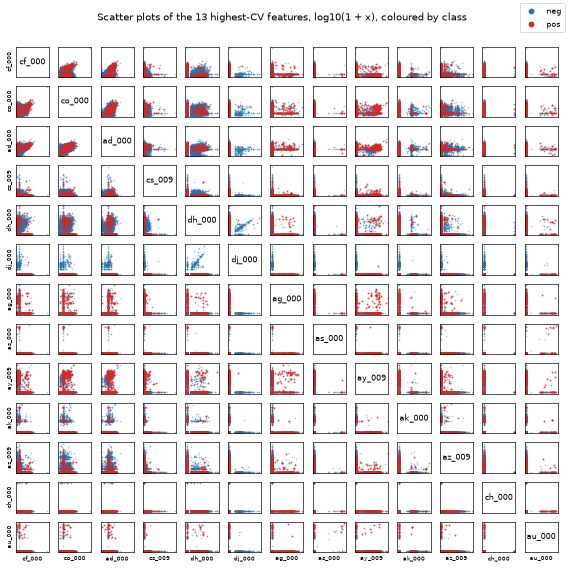

In [9]:
k = math.floor(math.sqrt(len(features)))
top = list(cv.index[:k])
print("floor(sqrt(170)) =", k)
print("the", k, "features with the highest CV:", top)
assert (X_train[top] >= 0).all().all() and (X_train_raw[features].min() >= 0).all()
print("every feature is non-negative: True")

Z = np.log10(1 + X_train[top])
pos = y_train == 1

fig, axes = plt.subplots(k, k, figsize=(9.5, 9.5), dpi=60)
for i, fi in enumerate(top):
    for j, fj in enumerate(top):
        ax = axes[i, j]
        if i == j:
            ax.text(0.5, 0.5, fi, ha="center", va="center", fontsize=9, transform=ax.transAxes)
        else:
            ax.scatter(Z[fj][~pos], Z[fi][~pos], s=1, c="tab:blue", alpha=0.3, rasterized=True)
            ax.scatter(Z[fj][pos], Z[fi][pos], s=2, c="tab:red", alpha=0.6, rasterized=True)
        ax.set_xticks([])
        ax.set_yticks([])
        if i == k - 1:
            ax.set_xlabel(fj, fontsize=7)
        if j == 0:
            ax.set_ylabel(fi, fontsize=7)
neg_dot = plt.Line2D([], [], marker="o", color="tab:blue", linestyle="", label="neg")
pos_dot = plt.Line2D([], [], marker="o", color="tab:red", linestyle="", label="pos")
fig.legend(handles=[neg_dot, pos_dot], loc="upper right")
fig.suptitle("Scatter plots of the 13 highest-CV features, log10(1 + x), coloured by class")
plt.tight_layout(rect=(0, 0, 1, 0.97))
plt.show()

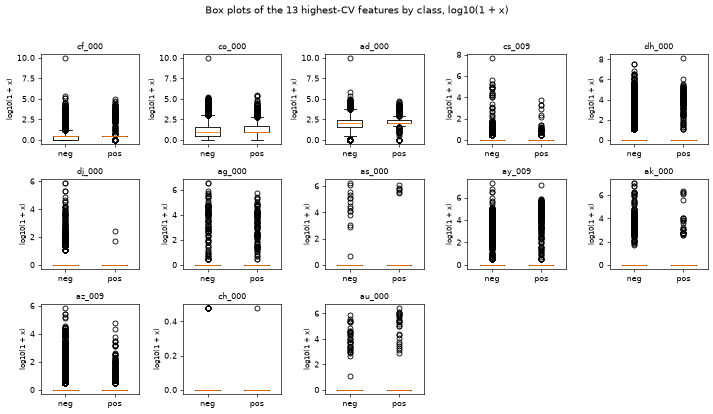

median and 75th percentile of each feature by class (original units):
        neg median  pos median  neg 75th percentile  pos 75th percentile
cf_000         2.0         2.0                  2.0                  2.0
co_000         8.0         8.0                 32.0                 46.0
ad_000       126.0       126.0                292.0                266.5
cs_009         0.0         0.0                  0.0                  0.0
dh_000         0.0         0.0                  0.0                  0.0
dj_000         0.0         0.0                  0.0                  0.0
ag_000         0.0         0.0                  0.0                  0.0
as_000         0.0         0.0                  0.0                  0.0
ay_009         0.0         0.0                  0.0                  0.0
ak_000         0.0         0.0                  0.0                  0.0
az_009         0.0         0.0                  0.0                  0.0
ch_000         0.0         0.0                  0.0   

In [10]:
fig, axes = plt.subplots(3, 5, figsize=(12, 7), dpi=60)
for ax, f in zip(axes.ravel(), top):
    ax.boxplot([Z[f][~pos], Z[f][pos]], tick_labels=["neg", "pos"], widths=0.5)
    ax.set_title(f, fontsize=10)
    ax.set_ylabel("log10(1 + x)", fontsize=8)
for ax in axes.ravel()[k:]:
    ax.axis("off")
fig.suptitle("Box plots of the 13 highest-CV features by class, log10(1 + x)")
plt.tight_layout(rect=(0, 0, 1, 0.96))
plt.show()

quartiles = pd.DataFrame({
    "neg median": X_train.loc[~pos, top].median(),
    "pos median": X_train.loc[pos, top].median(),
    "neg 75th percentile": X_train.loc[~pos, top].quantile(0.75),
    "pos 75th percentile": X_train.loc[pos, top].quantile(0.75)})
print("median and 75th percentile of each feature by class (original units):")
print(quartiles.to_string())

The 13 features with the highest CV are cf_000, co_000, ad_000, cs_009, dh_000, dj_000, ag_000, as_000, ay_009, ak_000, az_009, ch_000 and au_000.

No, the significance of these features cannot be judged from the scatter plots alone. A scatter plot shows how the two classes spread over two features. It does not show whether a feature has a significant effect once the other features are in a model. A high CV only means that a feature varies a lot relative to its mean. In the box plots the two classes have the same median for cf_000, co_000 and ad_000, 2, 8 and 126, and their boxes largely overlap. For the other ten features both classes have a median and a 75th percentile of 0, so each box is a line at 0 with a long tail of larger values. In the scatter plots the pos and neg points overlap in every panel, so no pair of these features separates the two classes on its own.

These 13 features are only used for the plots, as the handout says, and every model below uses all 170 features.

#### (v) Is this data set imbalanced?

The number of positive and negative rows is counted in the training set and in the test set, together with the share of positive rows.

In [11]:
counts = pd.DataFrame({"train": train["class"].value_counts(), "test": test["class"].value_counts()}).loc[["neg", "pos"]]
counts.loc["total"] = counts.sum()
print(counts.to_string())
print()
print("share of pos, train: %.4f   test: %.4f" % (y_train.mean(), y_test.mean()))
print("neg rows per pos row, train: %.1f   test: %.1f" % ((1 - y_train.mean()) / y_train.mean(), (1 - y_test.mean()) / y_test.mean()))

       train   test
class              
neg    59000  15625
pos     1000    375
total  60000  16000

share of pos, train: 0.0167   test: 0.0234
neg rows per pos row, train: 59.0   test: 41.7


Yes, the data set is imbalanced. The training set has 59000 neg rows and 1000 pos rows, so 1.67 percent of the rows are pos and there are 59 neg rows for every pos row. The test set has 15625 neg rows and 375 pos rows, so 2.34 percent are pos. A model that predicts neg for every row would be wrong on only 1.67 percent of the training rows, so the share of wrong predictions alone says little about a model here.

### (c) Train a random forest

A random forest with 500 fully grown trees is fitted on the imputed training set with all 170 features and with no compensation for class imbalance. For the training set and the test set the notebook reports the confusion matrix, the receiver operating characteristic (ROC) curve, the area under that curve (AUC) and the misclassification rate. The confusion matrix has the actual class in the rows and the predicted class in the columns. A row is predicted as pos when its predicted probability of pos is above 0.5, and the misclassification rate is the share of rows predicted wrongly at that threshold. The same threshold is used for every confusion matrix in this notebook.

The file aps_failure_description.txt that comes with the data defines a cost for the two kinds of errors. It says "Cost_1 = 10 and cost_2 = 500", where Cost_1 is the cost of an unneeded check by a mechanic and Cost_2 is the cost of missing a faulty truck. So a false alarm, a neg row predicted as pos, costs 10, and a missed failure, a pos row predicted as neg, costs 500. The tables below call them neg flagged and pos missed. The total cost is reported next to every confusion matrix, and it matters here because a missed failure costs 50 times more than a false alarm.

The out-of-bag (OOB) error is also computed. Each tree is grown on a bootstrap sample of the training rows, so about one third of the rows are left out of each tree. The OOB prediction of a row averages only the trees that did not see that row, so the OOB error is an estimate of the error on new data that uses only the training set [4]. The attribute oob_score_ is an accuracy, so the OOB error is 1 minus that value, and the OOB confusion matrix comes from oob_decision_function_ at the same threshold of 0.5. The training error, the OOB error and the test error below are the misclassification rates on the training rows, on the OOB predictions and on the test rows.

In [12]:
COST_NEG_AS_POS = 10    # a neg row predicted as pos, an unneeded workshop check
COST_POS_AS_NEG = 500   # a pos row predicted as neg, a missed faulty truck


def confusion_table(y_true, prob):
    """Confusion matrix at the 0.5 threshold, actual class in rows and predicted class in columns."""
    pred = (prob > 0.5).astype(int)
    cm = confusion_matrix(y_true, pred, labels=[1, 0])
    return pd.DataFrame(cm, index=["actual pos", "actual neg"], columns=["predicted pos", "predicted neg"])


def summarize(name, y_true, prob):
    """Print the confusion matrix, the misclassification rate, the AUC and the cost, and return them."""
    cm = confusion_table(y_true, prob)
    pos_missed = int(cm.loc["actual pos", "predicted neg"])
    neg_flagged = int(cm.loc["actual neg", "predicted pos"])
    result = {"misclassification": (pos_missed + neg_flagged) / len(y_true),
              "pos missed": pos_missed, "pos total": int((y_true == 1).sum()),
              "neg flagged": neg_flagged, "neg total": int((y_true == 0).sum()),
              "AUC": roc_auc_score(y_true, prob),
              "cost": COST_NEG_AS_POS * neg_flagged + COST_POS_AS_NEG * pos_missed}
    print(name)
    print(cm.to_string())
    print("misclassification rate: %.5f   AUC: %.4f   pos missed: %d of %d   neg flagged: %d of %d   cost: %d"
          % (result["misclassification"], result["AUC"], pos_missed, result["pos total"],
             neg_flagged, result["neg total"], result["cost"]))
    print()
    return result


def plot_roc(ax, curves, title):
    """ROC curves with the AUC in the legend. curves is a list of (label, y_true, prob)."""
    for label, y_true, prob in curves:
        fpr, tpr, _ = roc_curve(y_true, prob)
        ax.plot(fpr, tpr, label="%s (AUC = %.4f)" % (label, roc_auc_score(y_true, prob)))
    ax.plot([0, 1], [0, 1], color="gray", linestyle=":", label="chance")
    ax.set_xlabel("false positive rate")
    ax.set_ylabel("true positive rate")
    ax.set_title(title)
    ax.legend(loc="lower right")

In [13]:
rf = RandomForestClassifier(n_estimators=500, oob_score=True, random_state=0, n_jobs=-1)
rf.fit(X_train.values, y_train)

rf_train_prob = rf.predict_proba(X_train.values)[:, 1]
rf_oob_prob = rf.oob_decision_function_[:, 1]
rf_test_prob = rf.predict_proba(X_test.values)[:, 1]

rf_results = {}
rf_results["train"] = summarize("random forest, training set", y_train, rf_train_prob)
rf_results["OOB"] = summarize("random forest, out-of-bag on the training set", y_train, rf_oob_prob)
rf_results["test"] = summarize("random forest, test set", y_test, rf_test_prob)
print("OOB error from oob_score_: %.5f" % (1 - rf.oob_score_))
print("training error: %.5f   OOB error: %.5f   test error: %.5f"
      % (rf_results["train"]["misclassification"], rf_results["OOB"]["misclassification"], rf_results["test"]["misclassification"]))

random forest, training set
            predicted pos  predicted neg
actual pos           1000              0
actual neg              0          59000
misclassification rate: 0.00000   AUC: 1.0000   pos missed: 0 of 1000   neg flagged: 0 of 59000   cost: 0

random forest, out-of-bag on the training set
            predicted pos  predicted neg
actual pos            720            280
actual neg             73          58927
misclassification rate: 0.00588   AUC: 0.9865   pos missed: 280 of 1000   neg flagged: 73 of 59000   cost: 140730

random forest, test set
            predicted pos  predicted neg
actual pos            272            103
actual neg             18          15607
misclassification rate: 0.00756   AUC: 0.9943   pos missed: 103 of 375   neg flagged: 18 of 15625   cost: 51680

OOB error from oob_score_: 0.00588
training error: 0.00000   OOB error: 0.00588   test error: 0.00756


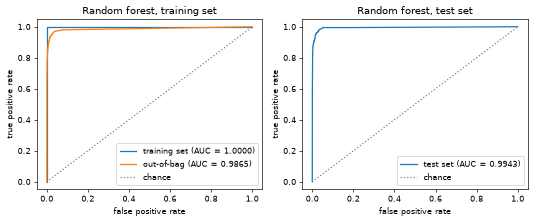

In [14]:
fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), dpi=60)
plot_roc(axes[0], [("training set", y_train, rf_train_prob), ("out-of-bag", y_train, rf_oob_prob)], "Random forest, training set")
plot_roc(axes[1], [("test set", y_test, rf_test_prob)], "Random forest, test set")
plt.tight_layout()
plt.show()

On the training set the forest makes no error at all, with a misclassification rate of 0.00000, an AUC of 1.0000 and a cost of 0. This number says nothing about new data. The trees are fully grown and every tree has seen most of the training rows, so the forest reproduces the training labels it was fitted on, and the training ROC curve is the top left corner of the plot.

The OOB error is the honest estimate from the training set, because every row is scored only by the trees that did not see it. The OOB error is 0.00588, which is 1 minus the OOB accuracy of 0.99412. The OOB AUC is 0.9865 and the OOB cost is 140730. The test error is 0.00756, with a test AUC of 0.9943 and a cost of 51680. The OOB error and the test error are close, 0.00588 against 0.00756, and both are far from the training error of 0. Within each class the two agree even more closely. The OOB matrix misses 280 of 1000 pos rows, or 28 percent, and the test matrix misses 103 of 375, or 27 percent. Both flag about 0.1 percent of the neg rows, 73 of 59000 and 18 of 15625. The test error is a little higher mainly because 2.34 percent of the test rows are pos, against 1.67 percent of the training rows. So the OOB error estimates the test error well, while the training error does not.

The misclassification rate hides the missed failures. A test error of 0.00756 sounds small, but it means that 103 of the 375 failures in the test set are missed. The rate is small because 98 percent of the test rows are neg and the forest gets almost all of them right.

### (d) Research class imbalance in random forest

Chen, Liaw and Breiman studied how a random forest can learn imbalanced data [5]. They propose two methods. The first is the weighted random forest, where each class gets a weight, the minority class gets the larger one, and the weights enter in two places. The class weights enter the Gini criterion when a split is chosen, and they weight the votes in the terminal nodes of each tree. The second is the balanced random forest. Every tree is grown on a bootstrap sample of the minority class together with a sample of the same size drawn with replacement from the majority class, so each tree sees a balanced data set. Their conclusion is that between the two methods there is no clear winner, and that the balanced random forest is computationally more efficient with large imbalanced data because each tree uses only a small part of the training set. A third and simpler option is to keep the forest of part (c) and move the decision threshold below 0.5, which trades more false alarms for fewer missed failures.

The balanced random forest is used here, for the reasons in the report. There is no clear winner between the two methods, and this training set is large and very imbalanced, which is the case where the balanced random forest is the more efficient one. This choice was made from the report before the model was run, and the other method is not tried.

The model is BalancedRandomForestClassifier from imbalanced-learn [6] with 500 trees. With sampling_strategy="all", replacement=True and bootstrap=False, each tree is grown on 1000 pos rows drawn with replacement and 1000 neg rows drawn with replacement, which is the balanced random forest of Chen, Liaw and Breiman. With bootstrap=False the class gives no OOB estimate, so the OOB prediction is computed from its definition in a short function. For each training row it averages the predicted probability of pos over the trees whose sample did not contain that row. The function is first checked on the forest of part (c), where it has to reproduce oob_decision_function_.

In [15]:
brf = BalancedRandomForestClassifier(n_estimators=500, sampling_strategy="all", replacement=True,
                                     bootstrap=False, random_state=0, n_jobs=-1)
brf.fit(X_train.values, y_train)
brf_train_prob = brf.predict_proba(X_train.values)[:, 1]
brf_test_prob = brf.predict_proba(X_test.values)[:, 1]
first_sample = brf.samplers_[0].sample_indices_
print("rows in the sample of the first tree:", len(first_sample), "  distinct rows:", len(np.unique(first_sample)),
      "  pos rows in it:", int(y_train[first_sample].sum()))

rows in the sample of the first tree: 2000   distinct rows: 1617   pos rows in it: 1000


In [16]:
def oob_probability(trees, samples, X):
    """OOB predicted probability of pos for every row of X.

    trees[t] is a fitted tree and samples[t] holds the row indices (with repeats) that
    tree t was grown on. Each row is averaged over the trees whose sample did not contain it.
    Returns the probabilities and the number of trees each row was out of bag for.
    """
    total = np.zeros(len(X))
    count = np.zeros(len(X))
    for tree, idx in zip(trees, samples):
        out = np.ones(len(X), dtype=bool)
        out[idx] = False
        total[out] += tree.predict_proba(X[out])[:, 1]
        count[out] += 1
    return total / count, count


# check on the forest of part (c): the function must reproduce oob_decision_function_
check_prob, check_count = oob_probability(rf.estimators_, rf.estimators_samples_, X_train.values)
print("largest difference from rf.oob_decision_function_: %.2e" % np.abs(check_prob - rf_oob_prob).max())
assert np.abs(check_prob - rf_oob_prob).max() < 1e-12
print("part (c) forest, smallest number of trees a row was out of bag for:", int(check_count.min()))

brf_oob_prob, brf_oob_count = oob_probability(brf.estimators_, [s.sample_indices_ for s in brf.samplers_], X_train.values)
print("balanced forest, smallest number of trees a row was out of bag for:", int(brf_oob_count.min()))
print("balanced forest, mean number of OOB trees, pos rows: %.1f   neg rows: %.1f"
      % (brf_oob_count[y_train == 1].mean(), brf_oob_count[y_train == 0].mean()))

largest difference from rf.oob_decision_function_: 0.00e+00
part (c) forest, smallest number of trees a row was out of bag for: 138


balanced forest, smallest number of trees a row was out of bag for: 147
balanced forest, mean number of OOB trees, pos rows: 183.8   neg rows: 491.6


balanced random forest, training set
            predicted pos  predicted neg
actual pos           1000              0
actual neg           2546          56454
misclassification rate: 0.04243   AUC: 0.9983   pos missed: 0 of 1000   neg flagged: 2546 of 59000   cost: 25460

balanced random forest, out-of-bag on the training set
            predicted pos  predicted neg
actual pos            964             36
actual neg           2616          56384
misclassification rate: 0.04420   AUC: 0.9851   pos missed: 36 of 1000   neg flagged: 2616 of 59000   cost: 44160

balanced random forest, test set
            predicted pos  predicted neg
actual pos            368              7
actual neg            647          14978
misclassification rate: 0.04088   AUC: 0.9930   pos missed: 7 of 375   neg flagged: 647 of 15625   cost: 9970

training error: 0.04243   OOB error: 0.04420   test error: 0.04088


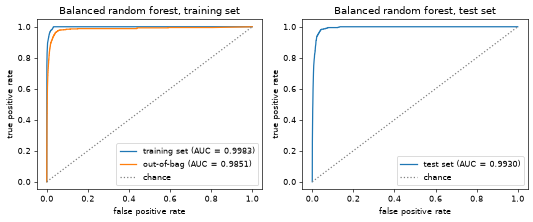

In [17]:
brf_results = {}
brf_results["train"] = summarize("balanced random forest, training set", y_train, brf_train_prob)
brf_results["OOB"] = summarize("balanced random forest, out-of-bag on the training set", y_train, brf_oob_prob)
brf_results["test"] = summarize("balanced random forest, test set", y_test, brf_test_prob)
print("training error: %.5f   OOB error: %.5f   test error: %.5f"
      % (brf_results["train"]["misclassification"], brf_results["OOB"]["misclassification"], brf_results["test"]["misclassification"]))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), dpi=60)
plot_roc(axes[0], [("training set", y_train, brf_train_prob), ("out-of-bag", y_train, brf_oob_prob)], "Balanced random forest, training set")
plot_roc(axes[1], [("test set", y_test, brf_test_prob)], "Balanced random forest, test set")
plt.tight_layout()
plt.show()

In [18]:
def compare_table(named_results, splits):
    rows = []
    for name, results in named_results:
        for split in splits:
            r = results[split]
            rows.append([name, split, r["misclassification"], r["pos missed"], r["pos total"], r["neg flagged"], r["neg total"], r["AUC"], r["cost"]])
    table = pd.DataFrame(rows, columns=["model", "rows", "misclassification", "pos missed", "pos total", "neg flagged", "neg total", "AUC", "cost"])
    return table


forest_table = compare_table([("random forest (c)", rf_results), ("balanced random forest (d)", brf_results)], ["train", "OOB", "test"])
print(forest_table.to_string(index=False, formatters={"misclassification": "{:.5f}".format, "AUC": "{:.4f}".format}))

                     model  rows misclassification  pos missed  pos total  neg flagged  neg total    AUC   cost
         random forest (c) train           0.00000           0       1000            0      59000 1.0000      0
         random forest (c)   OOB           0.00588         280       1000           73      59000 0.9865 140730
         random forest (c)  test           0.00756         103        375           18      15625 0.9943  51680
balanced random forest (d) train           0.04243           0       1000         2546      59000 0.9983  25460
balanced random forest (d)   OOB           0.04420          36       1000         2616      59000 0.9851  44160
balanced random forest (d)  test           0.04088           7        375          647      15625 0.9930   9970


Each tree of the balanced forest is grown on 2000 draws, 1000 from each class, and the first tree has 1617 distinct rows. Every training row is out of bag for at least 147 of the 500 trees, so the OOB prediction is defined for every row. The balanced forest has a training error of 0.04243, an OOB error of 0.04420 and a test error of 0.04088, with AUC 0.9983, 0.9851 and 0.9930 and cost 25460, 44160 and 9970. The OOB error is again close to the test error, so for this forest too the OOB error is a usable estimate of the test error. The training error is also close to both, because the neg rows that decide this rate are each seen by only about 8 of the 500 trees.

The table compares the two forests. On the test set the balanced forest misses 7 of the 375 pos rows, where the forest of part (c) misses 103. The balanced forest flags 647 of the 15625 neg rows, where the forest of part (c) flags 18. So the balanced forest has the higher test misclassification rate, 0.04088 against 0.00756, because the extra false alarms outnumber the failures it recovers. By the cost of the description file the balanced forest is much cheaper, 9970 against 51680, because one missed failure costs as much as 50 false alarms. The test AUC of the two forests is almost the same, 0.9930 against 0.9943, so the balancing mostly changes which rows pass the 0.5 threshold rather than how well the forest ranks the rows. Which forest is better depends on the measure, the forest of part (c) by the misclassification rate and the balanced forest by the number of missed failures and by the cost.

### (e) XGBoost and Model Trees

XGBoost fits a sum of small trees by gradient boosting, and with the logistic loss the sum of the leaf values gives the log-odds of pos. The L1 penalty of the handout is the XGBoost parameter reg_alpha. It adds alpha times the sum of the absolute leaf values to the loss, so it shrinks the leaf values toward 0 and can set some of them to exactly 0 [7]. This alpha is the regularization term of the handout, and it is the only setting that is tuned. The other settings are fixed and printed below. There is no compensation for class imbalance in this part.

The imputer and the model form one Pipeline. The pipeline is always fitted on the raw training features with their missing values, so inside each cross-validation fold the imputer learns its medians from the training part of the fold only and the held-out part is filled with those medians. The grid for alpha is 0 and 11 values from 0.001 to 100 on a log scale. The folds are stratified, because only 1000 of the 60000 rows are pos and a plain split could leave a fold with very few of them. The score is the AUC, because the misclassification rate barely moves when 98 percent of the rows are neg. The AUC also does not depend on the threshold or on the scale of the probabilities, which makes it comparable with part (f). If the chosen alpha were the largest or the smallest positive value of the grid, the grid would be extended in that direction and searched again.

In [19]:
xgb_settings = {"n_estimators": 200, "learning_rate": 0.1, "max_depth": 4, "tree_method": "hist",
                "random_state": 0, "n_jobs": -1}
print("fixed XGBoost settings:", xgb_settings)
print("objective:", XGBClassifier(**xgb_settings).objective)

alpha_grid = [0.0] + list(np.logspace(-3, 2, 11))
print("alpha grid:", ["%g" % a for a in alpha_grid])
cv_folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=0)
inner_folds = StratifiedKFold(n_splits=5, shuffle=True, random_state=1)

xgb_pipeline = Pipeline([("impute", SimpleImputer(strategy="median")),
                         ("xgb", XGBClassifier(**xgb_settings))])


def search_alpha(pipeline, grid):
    """Choose alpha by 5-fold cross-validation on the AUC. If the chosen alpha sits on the
    largest or the smallest positive grid value, the grid is extended that way and searched again."""
    grid = list(grid)
    for _ in range(4):
        search = GridSearchCV(pipeline, {"xgb__reg_alpha": grid}, cv=cv_folds, scoring="roc_auc")
        search.fit(X_train_raw.values, y_train)
        best = search.best_params_["xgb__reg_alpha"]
        positive = [a for a in grid if a > 0]
        if best == max(positive):
            print("chosen alpha %g is the largest grid value, extending the grid upward" % best)
            grid = sorted(grid + [max(positive) * 10 ** 0.5, max(positive) * 10])
        elif best == min(positive):
            print("chosen alpha %g is the smallest positive grid value, extending the grid downward" % best)
            grid = sorted(grid + [min(positive) / 10 ** 0.5, min(positive) / 10])
        else:
            if best == 0:
                print("chosen alpha is 0, so no penalty is best, and the grid is kept")
            else:
                print("chosen alpha %g is inside the grid, so the grid is kept" % best)
            return search, grid
    print("the grid was extended three times and the chosen alpha is still on an edge")
    return search, grid


def show_search(search):
    table = pd.DataFrame({"alpha": np.asarray(search.cv_results_["param_xgb__reg_alpha"], dtype=float),
                          "cross-validation AUC": search.cv_results_["mean_test_score"],
                          "std over folds": search.cv_results_["std_test_score"]})
    print(table.to_string(index=False, formatters={"alpha": "{:g}".format, "cross-validation AUC": "{:.5f}".format,
                                                   "std over folds": "{:.5f}".format}))
    best = search.best_params_["xgb__reg_alpha"]
    print("chosen alpha: %g   cross-validation AUC at the chosen alpha: %.5f" % (best, search.best_score_))
    print("cross-validation AUC over the whole grid: lowest %.5f, highest %.5f, difference %.5f"
          % (table["cross-validation AUC"].min(), table["cross-validation AUC"].max(),
             table["cross-validation AUC"].max() - table["cross-validation AUC"].min()))
    return table


def plot_search(table, best, title):
    fig, ax = plt.subplots(figsize=(6, 3.5), dpi=66)
    nonzero = table[table["alpha"] > 0]
    ax.plot(nonzero["alpha"], nonzero["cross-validation AUC"], marker="o", label="alpha > 0")
    ax.axhline(float(table.loc[table["alpha"] == 0, "cross-validation AUC"].iloc[0]), color="gray", linestyle=":", label="alpha = 0")
    if best > 0:
        ax.axvline(best, color="red", linestyle="--", label="chosen alpha = %g" % best)
    ax.set_xscale("log")
    ax.set_xlabel("alpha, the L1 penalty (log scale)")
    ax.set_ylabel("cross-validation AUC")
    ax.set_title(title)
    ax.legend(loc="lower left")
    plt.tight_layout()
    plt.show()


xgb_search, xgb_grid = search_alpha(xgb_pipeline, alpha_grid)
xgb_alpha = xgb_search.best_params_["xgb__reg_alpha"]
xgb_cv_table = show_search(xgb_search)

fixed XGBoost settings: {'n_estimators': 200, 'learning_rate': 0.1, 'max_depth': 4, 'tree_method': 'hist', 'random_state': 0, 'n_jobs': -1}
objective: binary:logistic
alpha grid: ['0', '0.001', '0.00316228', '0.01', '0.0316228', '0.1', '0.316228', '1', '3.16228', '10', '31.6228', '100']


chosen alpha 0.316228 is inside the grid, so the grid is kept
     alpha cross-validation AUC std over folds
         0              0.98984        0.00480
     0.001              0.99004        0.00457
0.00316228              0.99016        0.00464
      0.01              0.99027        0.00477
 0.0316228              0.98967        0.00540
       0.1              0.99032        0.00403
  0.316228              0.99042        0.00438
         1              0.98936        0.00547
   3.16228              0.98966        0.00475
        10              0.98915        0.00516
   31.6228              0.98628        0.00539
       100              0.98179        0.00652
chosen alpha: 0.316228   cross-validation AUC at the chosen alpha: 0.99042
cross-validation AUC over the whole grid: lowest 0.98179, highest 0.99042, difference 0.00864


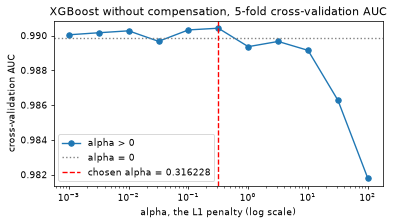

In [20]:
plot_search(xgb_cv_table, xgb_alpha, "XGBoost without compensation, 5-fold cross-validation AUC")

Cross-validation chooses alpha = 0.316, which is inside the grid, so the grid was not extended. The cross-validation AUC at the chosen alpha is 0.99042. The AUC changes very little across the grid, from 0.98179 at alpha = 100 to 0.99042 at the chosen value, a difference of 0.00864, and it stays above 0.989 for every alpha up to 10. The curve is nearly flat up to alpha = 10 and only drops at 31.6 and 100, where the penalty shrinks the leaf values too much. So the choice of alpha is a close one, and the standard deviation over the folds, about 0.005, is larger than most of the differences between the grid values.

The handout asks for a cross-validation estimate of the error of the trained model. The cross-validation AUC at the chosen alpha cannot be that estimate, because the same folds were used to pick alpha, so that number is the best of 12 tries and is optimistic. The honest estimate comes from nested cross-validation [8]. The training set is split into 5 outer folds. For each outer fold, a grid search over the same grid runs on the other four folds, with its own 5 inner folds, and chooses an alpha. The pipeline is refitted on those four folds with that alpha and scored on the outer held-out fold. Each outer held-out fold is therefore scored by a model whose alpha was chosen without it. The table shows the alpha chosen in each outer fold, the misclassification rate and the AUC of that fold, and their means.

In [21]:
def nested_estimate(pipeline, grid):
    inner = GridSearchCV(pipeline, {"xgb__reg_alpha": grid}, cv=inner_folds, scoring="roc_auc")
    nested = cross_validate(inner, X_train_raw.values, y_train, cv=cv_folds, scoring=["accuracy", "roc_auc"],
                            return_estimator=True)
    table = pd.DataFrame({"outer fold": range(1, 6),
                          "chosen alpha": [e.best_params_["xgb__reg_alpha"] for e in nested["estimator"]],
                          "misclassification": 1 - nested["test_accuracy"],
                          "AUC": nested["test_roc_auc"]})
    print(table.to_string(index=False, formatters={"chosen alpha": "{:g}".format, "misclassification": "{:.5f}".format, "AUC": "{:.5f}".format}))
    print("mean misclassification: %.5f   mean AUC: %.5f" % (table["misclassification"].mean(), table["AUC"].mean()))
    return table


xgb_nested = nested_estimate(xgb_pipeline, xgb_grid)

 outer fold chosen alpha misclassification     AUC
          1         0.01           0.00508 0.98381
          2           10           0.00642 0.99258
          3      3.16228           0.00575 0.99668
          4      3.16228           0.00617 0.98540
          5           10           0.00750 0.99011
mean misclassification: 0.00618   mean AUC: 0.98972


The five outer folds chose alpha = 0.01, 10, 3.162, 3.162 and 10, so the inner searches did not agree on one value. The reason is the flat cross-validation curve of the grid search. The AUC differs so little between the grid values that a different set of folds picks a different alpha. The nested cross-validation misclassification rate is between 0.00508 and 0.00750 over the outer folds, with a mean of 0.00618, and the nested AUC has a mean of 0.98972. This mean AUC is below the 0.99042 of the plain grid search, which is what one expects, because the plain value is the best of 12 tries on the same folds and the nested value is not.

The final model is the pipeline refitted by the grid search on the whole training set with the chosen alpha. Its training metrics are computed on the 60000 imputed training rows. The imputer of the final model was fitted on all 60000 rows, so its medians are the training medians of part (b). The test metrics use the test set filled with the test medians of part (b), which is passed to the pipeline with nothing left to impute.

the final model's imputer medians equal the training medians of part (b): True
final alpha: 0.316228


XGBoost without compensation, training set
            predicted pos  predicted neg
actual pos            943             57
actual neg              4          58996
misclassification rate: 0.00102   AUC: 0.9998   pos missed: 57 of 1000   neg flagged: 4 of 59000   cost: 28540

XGBoost without compensation, test set
            predicted pos  predicted neg
actual pos            291             84
actual neg             19          15606
misclassification rate: 0.00644   AUC: 0.9957   pos missed: 84 of 375   neg flagged: 19 of 15625   cost: 42190

nested cross-validation: misclassification 0.00618, AUC 0.98972
test set:               misclassification 0.00644, AUC 0.99571


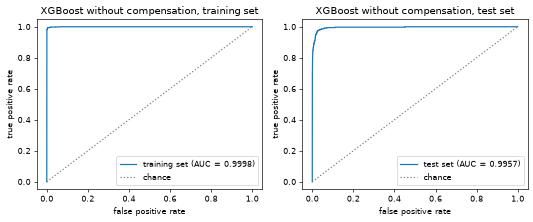

In [22]:
xgb_final = xgb_search.best_estimator_
assert np.allclose(xgb_final.named_steps["impute"].statistics_, train_medians.values)
print("the final model's imputer medians equal the training medians of part (b): True")
print("final alpha: %g" % xgb_final.named_steps["xgb"].reg_alpha)

xgb_train_prob = xgb_final.predict_proba(X_train_raw.values)[:, 1]
xgb_test_prob = xgb_final.predict_proba(X_test.values)[:, 1]
xgb_results = {}
xgb_results["train"] = summarize("XGBoost without compensation, training set", y_train, xgb_train_prob)
xgb_results["test"] = summarize("XGBoost without compensation, test set", y_test, xgb_test_prob)
print("nested cross-validation: misclassification %.5f, AUC %.5f" % (xgb_nested["misclassification"].mean(), xgb_nested["AUC"].mean()))
print("test set:               misclassification %.5f, AUC %.5f" % (xgb_results["test"]["misclassification"], xgb_results["test"]["AUC"]))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), dpi=60)
plot_roc(axes[0], [("training set", y_train, xgb_train_prob)], "XGBoost without compensation, training set")
plot_roc(axes[1], [("test set", y_test, xgb_test_prob)], "XGBoost without compensation, test set")
plt.tight_layout()
plt.show()

On the training set the final model has a misclassification rate of 0.00102, an AUC of 0.9998 and a cost of 28540, with 57 pos rows missed and 4 neg rows flagged. These training numbers come from the rows the model was fitted on, so they do not estimate the error on new data. On the test set the misclassification rate is 0.00644, the AUC is 0.9957 and the cost is 42190. The model misses 84 of the 375 pos rows and flags 19 of the 15625 neg rows. The nested cross-validation estimate of 0.00618 is close to the test misclassification rate of 0.00644, and the nested AUC of 0.98972 is a little below the test AUC of 0.9957, so the nested cross-validation gave a fair picture of the test performance.

### (f) Use SMOTE to pre-process your data

SMOTE (Synthetic Minority Over-sampling Technique) adds synthetic pos rows. For each pos row it picks one of its 5 nearest pos neighbours and places a new row at a random point on the segment between the two [9]. Here it is run until the pos class has as many rows as the neg class. There is a right and a wrong way to combine it with cross-validation. The wrong way applies SMOTE to the whole training set first and then cross-validates. A synthetic row built from a held-out row and its neighbour then sits in the training part of a fold, and other synthetic rows sit in the held-out part. The held-out fold is then no longer new data, and the score comes out too optimistic. The right way applies SMOTE only to the training part of each fold, scores on real held-out rows only, and never touches the test set. The imbalanced-learn Pipeline does exactly this, because it applies a sampler when the pipeline is fitted and never when it predicts [10, 11].

The pipeline has four steps. The imputer fills missing values with medians, a StandardScaler puts every feature on the same scale, SMOTE adds the synthetic pos rows, and then the XGBoost model of part (e) is fitted. The scaler is there because SMOTE finds nearest neighbours by distance and the raw features differ by many orders of magnitude, so without it a few large features would decide every neighbour. The trees of XGBoost do not depend on the scale of the features, so the scaler does not change the model itself. SMOTE runs on the full training set inside each fold, with no down-sampling of the neg class, as footnote 4 of the handout asks. Part (e) is then repeated with this pipeline. The same grid, the same folds, the same AUC score, the same grid-edge rule and the same nested cross-validation are used, so that the two cases can be compared.

In [23]:
smote_pipeline = Pipeline([("impute", SimpleImputer(strategy="median")),
                           ("scale", StandardScaler()),
                           ("smote", SMOTE(random_state=0)),
                           ("xgb", XGBClassifier(**xgb_settings))])

smote_search, smote_grid = search_alpha(smote_pipeline, alpha_grid)
smote_alpha = smote_search.best_params_["xgb__reg_alpha"]
smote_cv_table = show_search(smote_search)

chosen alpha 0.00316228 is inside the grid, so the grid is kept
     alpha cross-validation AUC std over folds
         0              0.98757        0.00454
     0.001              0.98793        0.00465
0.00316228              0.98813        0.00361
      0.01              0.98788        0.00443
 0.0316228              0.98774        0.00415
       0.1              0.98705        0.00483
  0.316228              0.98732        0.00482
         1              0.98789        0.00439
   3.16228              0.98738        0.00474
        10              0.98784        0.00337
   31.6228              0.98757        0.00321
       100              0.98624        0.00401
chosen alpha: 0.00316228   cross-validation AUC at the chosen alpha: 0.98813
cross-validation AUC over the whole grid: lowest 0.98624, highest 0.98813, difference 0.00189


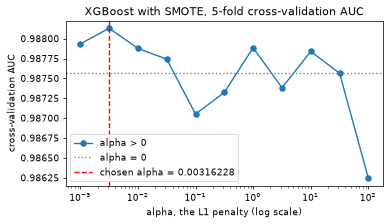

In [24]:
plot_search(smote_cv_table, smote_alpha, "XGBoost with SMOTE, 5-fold cross-validation AUC")

With SMOTE, cross-validation chooses alpha = 0.00316, which is inside the grid, so the grid was not extended. The cross-validation AUC at the chosen alpha is 0.98813. The whole grid lies between 0.98624 and 0.98813, a difference of only 0.00189, and the curve goes up and down with no clear trend until alpha = 100. The standard deviation over the folds, about 0.004, is larger than the whole range of the curve, so the chosen alpha is close to a tie with most of the other grid values. The highest cross-validation AUC with SMOTE, 0.98813, is below the 0.99042 of part (e), and SMOTE has the lower cross-validation AUC at every alpha from 0 to 10.

The nested cross-validation of part (e) is repeated with the SMOTE pipeline. Inside every inner and outer fold, SMOTE is applied to the training part only, so every score below is computed on real rows.

In [25]:
smote_nested = nested_estimate(smote_pipeline, smote_grid)

 outer fold chosen alpha misclassification     AUC
          1            1           0.01033 0.98004
          2         0.01           0.01000 0.98851
          3      31.6228           0.01233 0.99082
          4          100           0.02125 0.98155
          5            1           0.00867 0.99021
mean misclassification: 0.01252   mean AUC: 0.98623


The five outer folds chose alpha = 1, 0.01, 31.62, 100 and 1, which spread from 0.01 to 100, so the choice of alpha is even less stable than in part (e). One outer fold chose 100, the largest grid value, because the inner searches of the nested cross-validation use the fixed grid and are not extended. The nested misclassification rate is between 0.00867 and 0.02125 over the outer folds, with a mean of 0.01252, and the nested AUC has a mean of 0.98623. Compared with part (e), the nested misclassification rate is about twice as high, 0.01252 against 0.00618, while the nested AUC is only a little lower, 0.98623 against 0.98972.

The final SMOTE model is the pipeline refitted by the grid search on the whole training set. The number of rows it was fitted on after SMOTE is printed by repeating the first three steps of the fitted pipeline with the same random seed. The training metrics below are computed on the 60000 real training rows, not on the rows after SMOTE. The test metrics use the test set filled with the test medians, exactly as in part (e).

final alpha: 0.00316228


rows before SMOTE: 60000 (neg 59000, pos 1000)
rows the final model was fitted on after SMOTE: 118000 (neg 59000, pos 59000)


XGBoost with SMOTE, training set (60000 real rows)
            predicted pos  predicted neg
actual pos            961             39
actual neg            293          58707
misclassification rate: 0.00553   AUC: 0.9989   pos missed: 39 of 1000   neg flagged: 293 of 59000   cost: 22430

XGBoost with SMOTE, test set
            predicted pos  predicted neg
actual pos            334             41
actual neg            217          15408
misclassification rate: 0.01613   AUC: 0.9923   pos missed: 41 of 375   neg flagged: 217 of 15625   cost: 22670

nested cross-validation: misclassification 0.01252, AUC 0.98623
test set:               misclassification 0.01613, AUC 0.99234


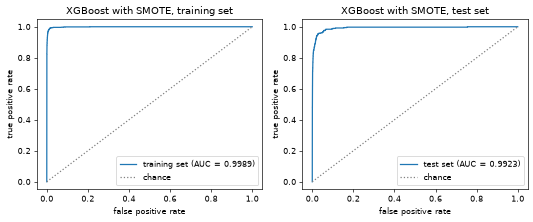

In [26]:
smote_final = smote_search.best_estimator_
assert np.allclose(smote_final.named_steps["impute"].statistics_, train_medians.values)
print("final alpha: %g" % smote_final.named_steps["xgb"].reg_alpha)

scaled_train = smote_final.named_steps["scale"].transform(smote_final.named_steps["impute"].transform(X_train_raw.values))
X_resampled, y_resampled = SMOTE(random_state=0).fit_resample(scaled_train, y_train)
print("rows before SMOTE: %d (neg %d, pos %d)" % (len(y_train), (y_train == 0).sum(), (y_train == 1).sum()))
print("rows the final model was fitted on after SMOTE: %d (neg %d, pos %d)"
      % (len(y_resampled), (y_resampled == 0).sum(), (y_resampled == 1).sum()))

smote_train_prob = smote_final.predict_proba(X_train_raw.values)[:, 1]
smote_test_prob = smote_final.predict_proba(X_test.values)[:, 1]
assert len(smote_train_prob) == 60000
smote_results = {}
smote_results["train"] = summarize("XGBoost with SMOTE, training set (60000 real rows)", y_train, smote_train_prob)
smote_results["test"] = summarize("XGBoost with SMOTE, test set", y_test, smote_test_prob)
print("nested cross-validation: misclassification %.5f, AUC %.5f" % (smote_nested["misclassification"].mean(), smote_nested["AUC"].mean()))
print("test set:               misclassification %.5f, AUC %.5f" % (smote_results["test"]["misclassification"], smote_results["test"]["AUC"]))

fig, axes = plt.subplots(1, 2, figsize=(9, 3.8), dpi=60)
plot_roc(axes[0], [("training set", y_train, smote_train_prob)], "XGBoost with SMOTE, training set")
plot_roc(axes[1], [("test set", y_test, smote_test_prob)], "XGBoost with SMOTE, test set")
plt.tight_layout()
plt.show()

In [27]:
rows = []
for name, nested, results in [("XGBoost without compensation (e)", xgb_nested, xgb_results), ("XGBoost with SMOTE (f)", smote_nested, smote_results)]:
    t = results["test"]
    rows.append([name, nested["misclassification"].mean(), nested["AUC"].mean(), t["misclassification"], t["AUC"],
                 t["pos missed"], t["pos total"], t["neg flagged"], t["neg total"], t["cost"]])
xgb_table = pd.DataFrame(rows, columns=["model", "nested misclassification", "nested AUC", "test misclassification", "test AUC",
                                        "test pos missed", "pos total", "test neg flagged", "neg total", "test cost"])
print(xgb_table.to_string(index=False, formatters={c: "{:.5f}".format for c in ["nested misclassification", "nested AUC", "test misclassification", "test AUC"]}))

                           model nested misclassification nested AUC test misclassification test AUC  test pos missed  pos total  test neg flagged  neg total  test cost
XGBoost without compensation (e)                  0.00618    0.98972                0.00644  0.99571               84        375                19      15625      42190
          XGBoost with SMOTE (f)                  0.01252    0.98623                0.01613  0.99234               41        375               217      15625      22670


The table compares the two cases. On the test set the SMOTE model misses 41 of the 375 pos rows, where the uncompensated model misses 84, so SMOTE recovers 43 failures. The SMOTE model flags 217 of the 15625 neg rows, where the uncompensated model flags 19, so SMOTE adds 198 false alarms. The SMOTE model therefore has the higher test misclassification rate, 0.01613 against 0.00644, and also the higher nested cross-validation misclassification rate, 0.01252 against 0.00618. By the cost of the description file the SMOTE model is cheaper, 22670 against 42190, because the 43 recovered failures save more than the 198 extra false alarms cost. The AUC is slightly lower with SMOTE, 0.9923 against 0.9957 on the test set and 0.98623 against 0.98972 in the nested cross-validation, so SMOTE does not rank the rows better. It moves more rows across the 0.5 threshold into the pos class. Which case is better depends on the measure, the uncompensated model by the misclassification rate and the AUC, and the SMOTE model by the number of missed failures and by the cost.

## 2. ISLR 6.6.3

The lasso in its constrained form minimizes the training residual sum of squares (RSS) subject to $\sum_{j=1}^{p} |\beta_j| \le s$. At $s = 0$ every slope is 0, and as $s$ grows the constraint loosens and the fit becomes more flexible.

(a) Training RSS, answer (iv), steadily decrease. A larger $s$ allows every coefficient vector that a smaller $s$ allows, so the smallest training RSS can only go down. Once $s$ reaches the sum of the absolute least squares coefficients the constraint stops binding and the training RSS stays at the least squares value.

(b) Test RSS, answer (ii), decrease initially and then eventually start increasing in a U shape. For small $s$ the model is too simple and its bias dominates. As $s$ grows the bias falls faster than the variance rises, so the test RSS falls, and once the model starts fitting noise the variance dominates and the test RSS rises again.

(c) Variance, answer (iii), steadily increase. A larger $s$ lets the coefficients follow the training data more closely, so the fitted values change more from one training set to another.

(d) Squared bias, answer (iv), steadily decrease. A larger $s$ shrinks the coefficients less, so the fitted model gets closer to the true relationship on average.

(e) Irreducible error, answer (v), remain constant. It is the variance of the noise term, which does not depend on the model or on $s$.

## 3. ISLR 6.6.5

There are $n = 2$ observations and $p = 2$ features with $x_{11} = x_{12}$, $x_{21} = x_{22}$, $x_{11} + x_{21} = 0$, $x_{12} + x_{22} = 0$ and $y_1 + y_2 = 0$, and the intercept is $\beta_0 = 0$. Write $x_{11} = x_{12} = a$ with $a \neq 0$, so $x_{21} = x_{22} = -a$ and $y_2 = -y_1$.

(a) The ridge regression problem is to minimize

$(y_1 - \beta_1 x_{11} - \beta_2 x_{12})^2 + (y_2 - \beta_1 x_{21} - \beta_2 x_{22})^2 + \lambda (\beta_1^2 + \beta_2^2)$,

which with the given values is $(y_1 - a\beta_1 - a\beta_2)^2 + (-y_1 + a\beta_1 + a\beta_2)^2 + \lambda(\beta_1^2 + \beta_2^2) = 2(y_1 - a(\beta_1 + \beta_2))^2 + \lambda(\beta_1^2 + \beta_2^2)$.

(b) Setting the partial derivatives to 0 gives $-4a(y_1 - a(\beta_1 + \beta_2)) + 2\lambda\beta_1 = 0$ and $-4a(y_1 - a(\beta_1 + \beta_2)) + 2\lambda\beta_2 = 0$. The first terms are identical, so subtracting the two equations gives $2\lambda(\beta_1 - \beta_2) = 0$. For $\lambda > 0$ this forces $\hat\beta_1 = \hat\beta_2$. The ridge objective is strictly convex when $\lambda > 0$, so this is the unique minimizer.

(c) The lasso problem is to minimize the same RSS plus the L1 penalty,

$(y_1 - \beta_1 x_{11} - \beta_2 x_{12})^2 + (y_2 - \beta_1 x_{21} - \beta_2 x_{22})^2 + \lambda (|\beta_1| + |\beta_2|) = 2(y_1 - a(\beta_1 + \beta_2))^2 + \lambda(|\beta_1| + |\beta_2|)$.

(d) Let $t = \beta_1 + \beta_2$. The RSS depends on the coefficients only through $t$. The penalty satisfies $|\beta_1| + |\beta_2| \ge |t|$, with equality exactly when $\beta_1$ and $\beta_2$ have the same sign or one of them is 0. So for a fixed $t$ the objective is smallest, and equal to $2(y_1 - at)^2 + \lambda|t|$, when the two coefficients have the same sign. Minimizing that function of one variable gives a single value $t^*$. Every pair with $\beta_1 + \beta_2 = t^*$ and both coefficients of the same sign as $t^*$ reaches the same minimum, which is the whole segment from $(t^*, 0)$ to $(0, t^*)$. So when $t^* \neq 0$ the lasso coefficients are not unique, and there are many solutions. In the constrained form of the lasso this segment is one edge of the diamond $|\beta_1| + |\beta_2| \le s$, the edge that lies on the line $\beta_1 + \beta_2 = t^*$, and the RSS contours are straight lines parallel to that edge.

## 4. ISLR 8.4.5

Ten bootstrapped trees give these estimates of $P(\text{Class is Red} \mid X)$, 0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7 and 0.75. Under the majority vote, each tree votes Red when its estimate is above 0.5, and the class with more votes wins. Under the average probability, the ten estimates are averaged and the class is Red when the average is above 0.5. Both are computed below.

In [28]:
estimates = np.array([0.1, 0.15, 0.2, 0.2, 0.55, 0.6, 0.6, 0.65, 0.7, 0.75])
red_votes = int((estimates > 0.5).sum())
print("votes for Red: %d of %d, majority vote gives: %s" % (red_votes, len(estimates), "Red" if red_votes > len(estimates) / 2 else "Green"))
print("average probability of Red: %.2f, average probability gives: %s" % (estimates.mean(), "Red" if estimates.mean() > 0.5 else "Green"))

votes for Red: 6 of 10, majority vote gives: Red
average probability of Red: 0.45, average probability gives: Green


The majority vote classifies $X$ as Red, because 6 of the 10 trees give a probability above 0.5. The average probability classifies $X$ as Green, because the mean of the ten estimates is 0.45, which is below 0.5. The two approaches disagree here because the four Green votes are far below 0.5 while the six Red votes are only a little above it.

## 5. ISLR 9.7.3

The seven observations are Red at $(3, 4)$, $(2, 2)$, $(4, 4)$ and $(1, 4)$, and Blue at $(2, 1)$, $(4, 3)$ and $(4, 1)$. The parts are answered below the figure, which has one panel for parts (a), (b) and (d) together, one for part (e), one for part (g) and one for part (h).

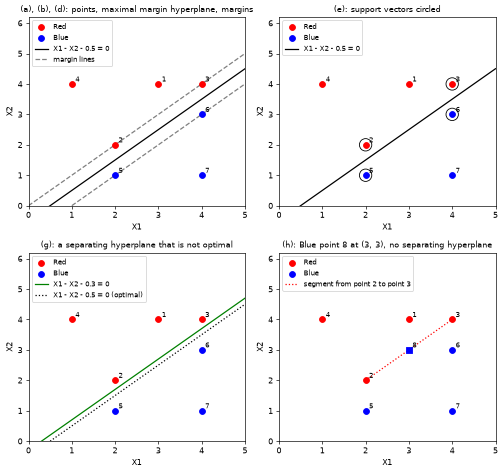

In [29]:
points = np.array([[3, 4], [2, 2], [4, 4], [1, 4], [2, 1], [4, 3], [4, 1]], dtype=float)
colors = ["red", "red", "red", "red", "blue", "blue", "blue"]
labels = np.array([1, 1, 1, 1, 0, 0, 0])
grid_x = np.linspace(0, 5, 2)


def draw_points(ax, title, extra=None):
    for n, ((x1, x2), c) in enumerate(zip(points, colors), start=1):
        ax.scatter(x1, x2, c=c, s=50, zorder=3)
        ax.annotate(str(n), (x1 + 0.08, x2 + 0.08), fontsize=8)
    if extra is not None:
        ax.scatter(extra[0], extra[1], c="blue", s=50, zorder=3, marker="s")
        ax.annotate("8", (extra[0] + 0.08, extra[1] + 0.08), fontsize=8)
    ax.set_xlim(0, 5)
    ax.set_ylim(0, 6.2)
    ax.set_xlabel("X1")
    ax.set_ylabel("X2")
    ax.set_title(title, fontsize=10)
    ax.scatter([], [], c="red", s=50, label="Red")
    ax.scatter([], [], c="blue", s=50, label="Blue")


fig, axes = plt.subplots(2, 2, figsize=(8.5, 8), dpi=60)
ax = axes[0, 0]
draw_points(ax, "(a), (b), (d): points, maximal margin hyperplane, margins")
ax.plot(grid_x, grid_x - 0.5, color="black", label="X1 - X2 - 0.5 = 0")
ax.plot(grid_x, grid_x, color="gray", linestyle="--", label="margin lines")
ax.plot(grid_x, grid_x - 1, color="gray", linestyle="--")
ax.legend(loc="upper left", fontsize=8)

ax = axes[0, 1]
draw_points(ax, "(e): support vectors circled")
ax.plot(grid_x, grid_x - 0.5, color="black", label="X1 - X2 - 0.5 = 0")
for n in [2, 3, 5, 6]:
    ax.scatter(points[n - 1, 0], points[n - 1, 1], s=220, facecolors="none", edgecolors="black", zorder=2)
ax.legend(loc="upper left", fontsize=8)

ax = axes[1, 0]
draw_points(ax, "(g): a separating hyperplane that is not optimal")
ax.plot(grid_x, grid_x - 0.3, color="green", label="X1 - X2 - 0.3 = 0")
ax.plot(grid_x, grid_x - 0.5, color="black", linestyle=":", label="X1 - X2 - 0.5 = 0 (optimal)")
ax.legend(loc="upper left", fontsize=8)

ax = axes[1, 1]
draw_points(ax, "(h): Blue point 8 at (3, 3), no separating hyperplane", extra=(3, 3))
ax.plot([2, 4], [2, 4], color="red", linestyle=":", label="segment from point 2 to point 3")
ax.legend(loc="upper left", fontsize=8)
plt.tight_layout()
plt.show()

In [30]:
svm = SVC(kernel="linear", C=1e6)
svm.fit(points, labels)
w = svm.coef_[0]
b = svm.intercept_[0]
print("coefficients (X1, X2): (%.4f, %.4f)   intercept: %.4f" % (w[0], w[1], b))
print("scaled by 1 / w[1]: (%.4f, %.4f)   intercept: %.4f" % (w[0] / w[1], w[1] / w[1], b / w[1]))
print("support vectors (observation numbers):", sorted(int(i) + 1 for i in svm.support_))
print("margin, 1 / ||w||: %.4f   and 0.5 / sqrt(2): %.4f" % (1 / np.linalg.norm(w), 0.5 / math.sqrt(2)))
dist7 = abs(points[6, 0] - points[6, 1] - 0.5) / math.sqrt(2)
print("distance of observation 7 from the hyperplane: %.4f" % dist7)

coefficients (X1, X2): (-1.9994, 1.9994)   intercept: 0.9997
scaled by 1 / w[1]: (-1.0000, 1.0000)   intercept: 0.5000
support vectors (observation numbers): [2, 3, 5, 6]
margin, 1 / ||w||: 0.3537   and 0.5 / sqrt(2): 0.3536
distance of observation 7 from the hyperplane: 1.7678


(a) The seven observations are shown in the first panel, Red as circles labelled 1 to 4 and Blue as circles labelled 5 to 7.

(b) The optimal separating hyperplane lies halfway between the line $X_2 = X_1$ through the Red points $(2, 2)$ and $(4, 4)$ and the line $X_2 = X_1 - 1$ through the Blue points $(2, 1)$ and $(4, 3)$. It is the line $X_1 - X_2 - 0.5 = 0$, or $X_2 = X_1 - 0.5$, drawn in black in the first panel.

(c) The rule is to classify to Red if $0.5 - X_1 + X_2 > 0$ and to Blue otherwise, so $\beta_0 = 0.5$, $\beta_1 = -1$ and $\beta_2 = 1$. Any positive multiple of these values gives the same rule.

(d) The margin is the distance from the hyperplane to the closest observations, which is $0.5 / \sqrt{2} \approx 0.354$. The two dashed lines $X_2 = X_1$ and $X_2 = X_1 - 1$ in the first panel are the margin lines.

(e) The support vectors are the observations on the margin lines, which are observations 2, 3, 5 and 6, at $(2, 2)$, $(4, 4)$, $(2, 1)$ and $(4, 3)$. They are circled in the second panel.

(f) Observation 7 at $(4, 1)$ is not a support vector. It lies about 1.77 from the hyperplane, well outside the margin, so a slight movement of this observation leaves the margin and the hyperplane unchanged.

(g) The line $X_1 - X_2 - 0.3 = 0$, drawn in green in the third panel, also separates the two classes, with the rule Red if $0.3 - X_1 + X_2 > 0$. It is not the optimal hyperplane because its margin is only $0.3 / \sqrt{2}$, which is smaller than $0.5 / \sqrt{2}$.

(h) A Blue observation at $(3, 3)$, shown as the square labelled 8 in the last panel, lies on the segment between the Red points $(2, 2)$ and $(4, 4)$. Any hyperplane that puts both of those Red points on the Red side puts the whole segment on that side, so the new Blue point cannot be separated and no separating hyperplane exists.

The scikit-learn SVC with a linear kernel and C = 1e6 confirms parts (b) to (f). In scikit-learn a large C puts a large penalty on any point inside the margin, which is the opposite of the budget $C$ of ISLR, so with C this large the fit is the maximal margin classifier. The coefficients of the SVC are a positive multiple of $(-1, 1)$ with intercept $0.5$ times the same multiple, its support vectors are observations 2, 3, 5 and 6, and its margin equals $0.5 / \sqrt{2}$.

## 6.1. Extra Practice ISLR 5.4.2

The assignment lists ISLR 5.4.2 as extra practice, and its answer is not submitted.

## 6.2. Extra Practice ISLR 6.8.4

The assignment lists ISLR 6.8.4 as extra practice, and its answer is not submitted.

## 6.3. Extra Practice ISLR 8.4.4

The assignment lists ISLR 8.4.4 as extra practice, and its answer is not submitted.

## 6.4. Extra Practice ISLR 9.7.2

The assignment lists ISLR 9.7.2 as extra practice, and its answer is not submitted.

## References

[1] UCI Machine Learning Repository, APS Failure at Scania Trucks data set. https://archive.ics.uci.edu/ml/datasets/APS+Failure+at+Scania+Trucks

[2] scikit-learn user guide, Imputation of missing values. https://scikit-learn.org/stable/modules/impute.html

[3] G. James, D. Witten, T. Hastie and R. Tibshirani, An Introduction to Statistical Learning with Applications in R, second edition, Springer, 2021.

[4] scikit-learn, RandomForestClassifier. https://scikit-learn.org/stable/modules/generated/sklearn.ensemble.RandomForestClassifier.html

[5] C. Chen, A. Liaw and L. Breiman, Using Random Forest to Learn Imbalanced Data, Technical Report 666, Department of Statistics, University of California, Berkeley, 2004. https://statistics.berkeley.edu/sites/default/files/tech-reports/666.pdf

[6] imbalanced-learn, BalancedRandomForestClassifier. https://imbalanced-learn.org/stable/references/generated/imblearn.ensemble.BalancedRandomForestClassifier.html

[7] XGBoost documentation, XGBoost Parameters. https://xgboost.readthedocs.io/en/stable/parameter.html

[8] scikit-learn, Nested versus non-nested cross-validation. https://scikit-learn.org/stable/auto_examples/model_selection/plot_nested_cross_validation_iris.html

[9] N. V. Chawla, K. W. Bowyer, L. O. Hall and W. P. Kegelmeyer, SMOTE: Synthetic Minority Over-sampling Technique, Journal of Artificial Intelligence Research 16 (2002) 321-357. https://www.jair.org/index.php/jair/article/view/10302

[10] imbalanced-learn, SMOTE. https://imbalanced-learn.org/stable/references/generated/imblearn.over_sampling.SMOTE.html

[11] imbalanced-learn, Pipeline. https://imbalanced-learn.org/stable/references/generated/imblearn.pipeline.Pipeline.html